# 14. Fourth-order problems: beams, plates and flow stability

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/14_fourth_order_problems.ipynb)

*Companion to Chapter 14 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

The bending of a beam or a plate is governed by a fourth derivative, and so is the stability of
a viscous shear flow. A fourth-order equation needs **two** boundary conditions at each end,
such as zero deflection and zero slope at a clamped support, or zero velocity and no slip at a
wall. The collocation matrices used so far have only one row per boundary point, so a new idea
is needed. With it, one small function handles a clamped beam, its vibration and buckling, a
clamped plate, and the Orr-Sommerfeld equation of hydrodynamic stability.

- building the clamped conditions into the unknown: $u = (1 - x^2)\,q$
- beam deflection, natural frequencies and buckling load
- the biharmonic equation on a square from Kronecker products
- the Orr-Sommerfeld equation as a generalized eigenvalue problem

**Worked examples:** a uniformly loaded beam, the modes of a clamped beam, Euler buckling, a
clamped square plate under pressure, and the critical Reynolds number of plane Poiseuille flow.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.linalg import eig, solve
from scipy.optimize import brentq

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

In [2]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

# barycentric_interpolate(values, x_eval) from notebook 4, used here to draw smooth curves
def barycentric_interpolate(values, x_eval):
    """Evaluate the polynomial interpolant through values at the Chebyshev points."""
    values = np.asarray(values, dtype=float)
    N = len(values) - 1
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    w = (-1.0) ** j
    w[0] /= 2
    w[N] /= 2
    x_eval = np.atleast_1d(np.asarray(x_eval, dtype=float))
    diff = x_eval[:, None] - x[None, :]
    exact = diff == 0
    diff[exact] = 1.0
    ratio = w / diff
    result = ratio @ values / ratio.sum(axis=1)
    hit_rows, hit_cols = np.nonzero(exact)
    result[hit_rows] = values[hit_cols]
    return result

x_plot = np.linspace(-1, 1, 201)

## 14.1 Four boundary conditions, two boundary points

**Problem.** Solve $u'''' = f$ on $[-1, 1]$ with the **clamped** conditions
$u(\pm1) = 0$ and $u'(\pm1) = 0$.

For second-order problems (notebook 6) the condition $u(\pm1) = 0$ was imposed by deleting the
first and last rows and columns of the matrix: the boundary values are known, so they are not
unknowns. That uses up the two boundary points. There is nowhere left to put $u'(\pm1) = 0$.

**By hand.** Build the extra conditions into the form of the solution. Write

$$u(x) = (1 - x^2)\,q(x),\qquad q(\pm1) = 0 .$$

Then $u(\pm1) = 0$ because of the factor $1 - x^2$, and
$u' = -2x\,q + (1 - x^2)\,q'$ vanishes at $x = \pm1$ as well: the second term because of the
factor, the first because $q(\pm1) = 0$. So if $q$ is a polynomial of degree $N$ that is zero
at both ends, which is exactly what the interior collocation unknowns of notebook 6 describe,
then $u$ satisfies all four conditions automatically. The product rule gives its fourth
derivative:

$$u'''' = (1 - x^2)\,q'''' + 4(-2x)\,q''' + 6(-2)\,q'' = (1 - x^2)\,q'''' - 8x\,q''' - 12\,q'' .$$

The unknowns are still the values of $u$ at the interior points, and $q_j = u_j/(1 - x_j^2)$
there. In matrix form

$$D^{(4)}_c = \Big[\operatorname{diag}(1 - x^2)\,D^4 - 8\operatorname{diag}(x)\,D^3 - 12\,D^2\Big]\operatorname{diag}\!\Big(\frac{1}{1 - x^2}\Big),$$

restricted to the interior rows and columns $1..N-1$. Deleting the boundary columns is what
imposes $q(\pm1) = 0$. This way of imposing the two conditions at each end is the one used in
Chapter 14 of the book.

The product rule is quickly confirmed by computer algebra.

In [3]:
xs = sp.symbols("x")
q = sp.Function("q")(xs)
product_rule = sp.diff((1 - xs**2) * q, xs, 4) - ((1 - xs**2) * sp.diff(q, xs, 4) - 8 * xs * sp.diff(q, xs, 3) - 12 * sp.diff(q, xs, 2))
assert sp.simplify(product_rule) == 0

def clamped_d4(N):
    """Fourth-derivative matrix on the interior Chebyshev points for functions with u = u' = 0 at x = ±1."""
    D, x = cheb(N)
    D2 = D @ D
    D3, D4 = D2 @ D, D2 @ D2
    weight = np.zeros(N + 1)
    weight[1:-1] = 1 / (1 - x[1:-1] ** 2)                    # q = u / (1 - x²) at the interior points
    operator = (np.diag(1 - x**2) @ D4 - 8 * np.diag(x) @ D3 - 12 * D2) @ np.diag(weight)
    return operator[1:-1, 1:-1]

**Verify** on a function that satisfies the clamped conditions and is not a polynomial:
$u = (1 - x^2)^2 e^{x}\sin 2x$, with its fourth derivative from computer algebra.

In [4]:
u_expr = (1 - xs**2) ** 2 * sp.exp(xs) * sp.sin(2 * xs)
u_exact, u4_exact = sp.lambdify(xs, u_expr), sp.lambdify(xs, sp.diff(u_expr, xs, 4))
print("  N    largest error in u''''")
for N in (8, 12, 16, 20, 24):
    x = cheb(N)[1][1:-1]
    error = np.abs(clamped_d4(N) @ u_exact(x) - u4_exact(x)).max()
    print(f"{N:3d}    {error:.1e}")
    if N == 20:
        assert error < 1e-8

  N    largest error in u''''
  8    1.0e+01
 12    5.9e-03
 16    2.7e-06
 20    1.7e-10
 24    4.4e-10


Spectral convergence, then a floor near $10^{-10}$ that rises with $N$. Four differentiations
amplify rounding errors by about $N^8$ (notebook 5 showed $N^2$ per derivative), so fourth-order
problems reward modest values of $N$ even more than second-order ones.

**Why not replace more rows?** The alternative is to keep all $N + 1$ unknowns and overwrite
four rows of $D^4$ with the four conditions: the two boundary rows and two more. It works, but
the choice of which two collocation equations to sacrifice is arbitrary, and in eigenvalue
problems the rows without the eigenvalue produce spurious infinite or very large eigenvalues
that have to be filtered out. (This is the row replacement of notebook 13, which is the right
tool when there is one condition per end and each has its own boundary row.) Building the
conditions into the unknown has neither problem.

## 14.2 Worked example: a uniformly loaded beam

**Problem.** A beam of length $L$ and bending stiffness $EI$ carries a uniform load $p$ per
unit length. Its deflection obeys $EI\,w'''' = p$. Measure $x$ from mid-span in units of
$L/2$ and $w$ in units of $p(L/2)^4/EI$: then $w'''' = 1$ on $[-1, 1]$. Compare a beam
**clamped** at both ends, $w = w' = 0$, with one that is **simply supported**, $w = w'' = 0$
(the supports hold the beam but exert no moment).

**By hand.** Clamped: $w$ is a quartic with double zeros at $\pm1$, so
$w = (1 - x^2)^2/24$. Simply supported: the bending moment $m = w''$ satisfies $m'' = 1$,
$m(\pm1) = 0$, so $m = (x^2 - 1)/2$; integrating twice more with $w(\pm1) = 0$ gives
$w = (x^4 - 6x^2 + 5)/24$. The second case is two second-order problems in a row, each with
one condition per end, and needs nothing beyond notebook 6.

largest errors: clamped 8.5e-15, simply supported 1.7e-15
centre deflections: clamped 0.041667 = 1/24, simply supported 0.208333 = 5/24, ratio 5.0000
bending moment w'' at the clamped end: 0.333333   exact 1/3


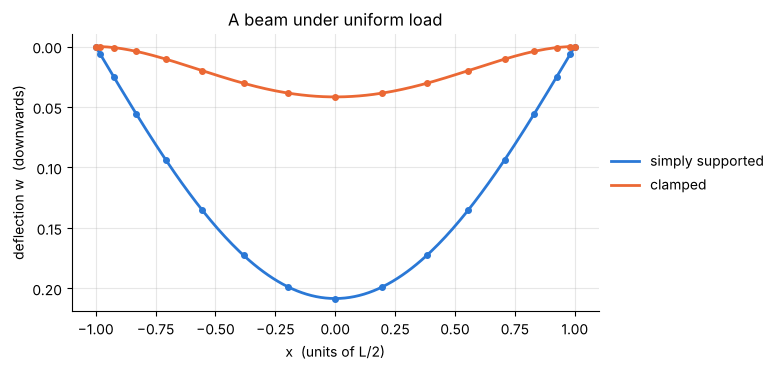

In [5]:
N = 16
D, x = cheb(N)
D2_full = D @ D
D2 = D2_full[1:N, 1:N]                                          # second derivative with u(±1) = 0
xi = x[1:N]
load = np.ones(N - 1)

w_clamped = solve(clamped_d4(N), load)
moment = solve(D2, load)                                        # m'' = 1, m(±1) = 0
w_simple = solve(D2, moment)                                    # w'' = m, w(±1) = 0

error_clamped = np.abs(w_clamped - (1 - xi**2) ** 2 / 24).max()
error_simple = np.abs(w_simple - (xi**4 - 6 * xi**2 + 5) / 24).max()
centre = N // 2 - 1                                             # x = 0 is interior point number N/2 - 1
wall_moment = (D2_full @ np.concatenate([[0], w_clamped, [0]]))[0]      # w'' at x = +1 (index 0)
print(f"largest errors: clamped {error_clamped:.1e}, simply supported {error_simple:.1e}")
print(f"centre deflections: clamped {w_clamped[centre]:.6f} = 1/24, simply supported {w_simple[centre]:.6f} = 5/24, ratio {w_simple[centre] / w_clamped[centre]:.4f}")
print(f"bending moment w'' at the clamped end: {wall_moment:.6f}   exact 1/3")
assert error_clamped < 1e-12 and error_simple < 1e-12
assert abs(w_simple[centre] / w_clamped[centre] - 5) < 1e-10 and abs(wall_moment - 1 / 3) < 1e-9

fig, ax = plt.subplots(figsize=(6.8, 3.6))
for w, name in ((w_simple, "simply supported"), (w_clamped, "clamped")):
    values = np.concatenate([[0], w, [0]])                      # add the end points, where w = 0
    line, = ax.plot(x_plot, barycentric_interpolate(values, x_plot), label=name)
    ax.plot(x, values, "o", ms=4, color=line.get_color())
ax.invert_yaxis()
ax.set(xlabel="x  (units of L/2)", ylabel="deflection w  (downwards)", title="A beam under uniform load")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

**What it means.** In the original units the centre deflections are $pL^4/(384\,EI)$ and
$5pL^4/(384\,EI)$, the two formulas in every structural handbook. Clamping the ends makes the
beam five times stiffer at mid-span. The price is a bending moment at the supports,
$w''(\pm1) = \tfrac13$, that is $pL^2/12$, twice the mid-span moment and the place where a
built-in beam fails first.

## 14.3 Worked example: vibration of a clamped beam

**Problem.** Free vibrations $w(x)\cos\omega t$ of a beam with mass $\rho A$ per unit length
satisfy $EI\,w'''' = \rho A\,\omega^2 w$. On $[-1, 1]$, with clamped ends, this is the
eigenvalue problem $w'''' = \lambda w$.

**By hand.** The solutions of $w'''' = \beta^4w$ are combinations of $\cos\beta x$,
$\sin\beta x$, $\cosh\beta x$, $\sinh\beta x$. Imposing the four clamped conditions on a beam
of unit length gives the frequency equation $\cosh b\,\cos b = 1$, with roots
$b = 4.730041,\ 7.853205,\ 10.995608, \dots$ The interval $[-1, 1]$ has length 2, so
$\beta = b/2$ and $\lambda = (b/2)^4$.

  b (unit length)   exact λ = (b/2)⁴    computed λ        error
   4.730041         31.28524386     31.28524386    2.1e-11
   7.853205        237.72106753    237.72106753    1.0e-11
   10.995608        913.60188320    913.60188320    2.6e-11
   14.137165       2496.48743786   2496.48743786    4.4e-11


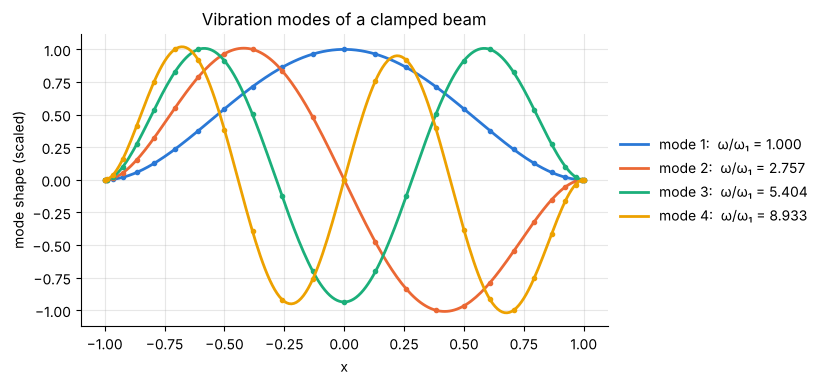

In [6]:
b = np.array([brentq(lambda s: np.cosh(s) * np.cos(s) - 1, (k + 0.5) * np.pi - 0.5, (k + 0.5) * np.pi + 0.5) for k in (1, 2, 3, 4)])
assert np.allclose(b[:3], [4.730041, 7.853205, 10.995608], atol=1e-6)

N = 24
D, x = cheb(N)
values, shapes = eig(clamped_d4(N))
order = np.argsort(values.real)
values, shapes = values[order].real, shapes[:, order].real
print("  b (unit length)   exact λ = (b/2)⁴    computed λ        error")
for bk, lam in zip(b, values):
    print(f"   {bk:.6f}      {(bk / 2) ** 4:14.8f}  {lam:14.8f}    {abs(lam - (bk / 2) ** 4):.1e}")
assert np.abs(values[:3] - (b[:3] / 2) ** 4).max() < 1e-8

fig, ax = plt.subplots(figsize=(6.8, 3.8))
for k in range(4):
    shape = np.concatenate([[0], shapes[:, k], [0]])
    shape = shape / shape[np.abs(shape).argmax()]
    line, = ax.plot(x_plot, barycentric_interpolate(shape, x_plot), label=f"mode {k + 1}:  ω/ω₁ = {np.sqrt(values[k] / values[0]):.3f}")
    ax.plot(x, shape, "o", ms=3, color=line.get_color())
ax.set(xlabel="x", ylabel="mode shape (scaled)", title="Vibration modes of a clamped beam")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

Every mode leaves the supports with zero slope, as a clamped beam must. In dimensional form
$\omega_k = (b_k/L)^2\sqrt{EI/\rho A}$, so the frequencies are in the ratios
$1 : 2.757 : 5.404 : 8.933$. Unlike a string, a beam has overtones that are far from multiples
of the fundamental, which is what a designer checks against the excitation frequencies of a
machine or of footfall on a floor.

## 14.4 Worked example: buckling of a clamped column

**Problem.** A column under an axial compressive force $P$ satisfies $EI\,w'''' + P\,w'' = 0$.
The straight state $w = 0$ is always a solution. The critical load is the smallest $P$ at which
a bent state also exists. With both ends clamped and lengths in units of $L/2$, find the
smallest eigenvalue of $w'''' = -P\,w''$, where $P$ is measured in units of $EI/(L/2)^2$.

**By hand.** Try $w = 1 + \cos\pi x$: it satisfies all four clamped conditions, and
$w'''' = \pi^4\cos\pi x = -\pi^2 w''$. So $P = \pi^2$, which in the original units is
$P_{cr} = 4\pi^2EI/L^2$.

The problem has an operator on **both** sides, a generalized eigenproblem
$D^{(4)}_c\mathbf{w} = P\,(-D^{(2)})\,\mathbf{w}$, as in notebook 8. For $w''$ the ordinary
second-derivative matrix with $w(\pm1) = 0$ is used.

In [7]:
N = 24
D, x = cheb(N)
D2 = (D @ D)[1:N, 1:N]
loads, shapes = eig(clamped_d4(N), -D2)
order = np.argsort(loads.real)
loads, shapes = loads[order].real, shapes[:, order].real
shape = shapes[:, 0] / shapes[N // 2 - 1, 0] * 2                 # scale to w(0) = 2, like 1 + cos πx
print(f"critical load P = {loads[0]:.10f}    π² = {np.pi**2:.10f}")
assert abs(loads[0] - np.pi**2) < 1e-8 and np.abs(shape - (1 + np.cos(np.pi * x[1:N]))).max() < 1e-8

critical load P = 9.8696044011    π² = 9.8696044011


**What it means.** A column with pinned ends buckles at $\pi^2EI/L^2$ (Euler's formula).
Clamping both ends raises the critical load by a factor of four, because the buckled shape
$1 + \cos\pi x$ has inflection points at the quarter points and the middle half of the column
behaves like a pinned column of length $L/2$. This is the "effective length factor 0.5" of
the design codes.

## 14.5 Worked example: a clamped square plate

**Problem.** A thin elastic plate with flexural rigidity $D_p$ carries a uniform pressure
$p$. Its deflection satisfies the **biharmonic equation**

$$\nabla^4 w = w_{xxxx} + 2\,w_{xxyy} + w_{yyyy} = \frac{p}{D_p} ,$$

and at a clamped edge $w = 0$ and $\partial w/\partial n = 0$. Find the deflection of a square
plate clamped on all four edges. Unlike the beam, this problem has no closed-form solution.
The accepted benchmark, from series solutions, is a centre deflection of
$0.00126532\,p\,a^4/D_p$ for a plate of side $a$.

**By hand.** Work on $[-1, 1]^2$ with $p/D_p = 1$, so $a = 2$ and the target is
$w(0, 0) = 0.00126532\times16 = 0.0202451$. Order the interior unknowns row by row as in
notebook 6, `W[i, j]` $= w(x_j, y_i)$. Then each term is a Kronecker product of
one-dimensional matrices:

$$L = I\otimes D^{(4)}_c \;+\; D^{(4)}_c\otimes I \;+\; 2\,D^{(2)}\otimes D^{(2)} .$$

The clamped conditions $w = w_x = 0$ on the edges $x = \pm1$ are carried by $D^{(4)}_c$ in the
first term, and those on $y = \pm1$ by the second. The mixed term uses the ordinary
second-derivative matrix with zero boundary values in each direction.

In [8]:
def clamped_plate(N):
    """Deflection of the clamped square plate [-1, 1]² under unit load. Returns W (interior values) and x."""
    D, x = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    D4 = clamped_d4(N)
    I = np.eye(N - 1)
    L = np.kron(I, D4) + np.kron(D4, I) + 2 * np.kron(D2, D2)
    return solve(L, np.ones((N - 1) ** 2)).reshape(N - 1, N - 1), x

benchmark = 0.00126532                                         # centre deflection in units of p a⁴ / D_p
print("  N   unknowns    w(0,0)             w(0,0)/16")
centre_values = {}
for N in (8, 12, 16, 20, 24, 28):
    W, x = clamped_plate(N)
    centre_values[N] = W[N // 2 - 1, N // 2 - 1]
    print(f"{N:3d}   {(N - 1) ** 2:6d}    {centre_values[N]:.12f}   {centre_values[N] / 16:.12f}")
assert abs(centre_values[28] / 16 - benchmark) < 5e-9          # all six digits of the benchmark
assert abs(centre_values[8] / 16 - benchmark) < 5e-9
changes = np.abs(np.diff(list(centre_values.values())))
assert np.all(changes[1:] < changes[:-1]) and changes[-1] < 1e-11

  N   unknowns    w(0,0)             w(0,0)/16
  8       49    0.020245146198   0.001265321637
 12      121    0.020245104657   0.001265319041
 16      225    0.020245105430   0.001265319089
 20      361    0.020245105406   0.001265319088
 24      529    0.020245105400   0.001265319088
 28      729    0.020245105400   0.001265319087


The benchmark is reproduced to all its digits, and already with $N = 8$ (49 unknowns) the
centre deflection is right to six figures. The changes from one $N$ to the next keep
shrinking. Convergence is fast, though in the end algebraic and not geometric: as for the
square duct of notebook 6, the corners limit the smoothness of the solution.

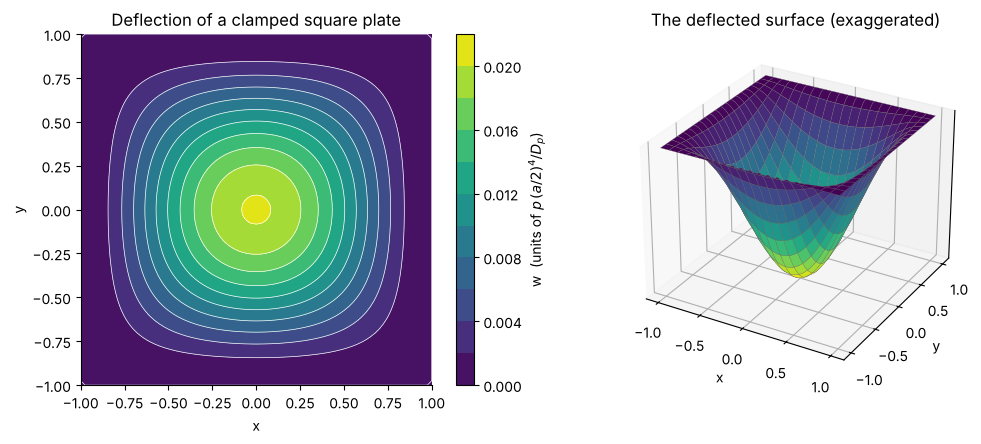

In [9]:
W, x = clamped_plate(28)
full = np.zeros((29, 29))
full[1:-1, 1:-1] = W                                            # add the clamped edges, where w = 0
x_fine = np.linspace(-1, 1, 81)                                 # a finer grid for the picture: interpolate in x, then in y
rows = np.array([barycentric_interpolate(row, x_fine) for row in full])
full = np.array([barycentric_interpolate(column, x_fine) for column in rows.T]).T
X, Y = np.meshgrid(x_fine, x_fine)

fig = plt.figure(figsize=(11, 4.4))
ax1 = fig.add_subplot(1, 2, 1)
filled = ax1.contourf(X, Y, full, levels=12, cmap="viridis")
ax1.contour(X, Y, full, levels=12, colors="w", linewidths=0.5)
ax1.set(xlabel="x", ylabel="y", title="Deflection of a clamped square plate", aspect="equal")
ax1.grid(False)
fig.colorbar(filled, ax=ax1, label="w  (units of $p\\,(a/2)^4/D_p$)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(X, Y, -full, cmap="viridis_r", rstride=4, cstride=4, linewidth=0.2, edgecolor="0.4")
ax2.set(xlabel="x", ylabel="y", title="The deflected surface (exaggerated)", zticks=[])
ax2.view_init(elev=28, azim=-60)
fig.tight_layout()

**What it means.** The contours are nearly circular in the middle and squeeze into the shape
of the boundary towards the edges; the plate leaves every edge with zero slope, and the corners
hardly move. A simply supported plate of the same size deflects 3.2 times as much (exercise 3).
Numbers of this kind sit behind the tables used to size tank walls, pressure-vessel covers
and floor panels.

**A remark on the mixed term.** One might worry that $D^{(2)}\otimes D^{(2)}$ knows nothing
about the zero slopes. A variant that builds the factor $(1 - x^2)$ into the second derivative
as well, $[\operatorname{diag}(1 - x^2)D^2 - 4\operatorname{diag}(x)D - 2I]\operatorname{diag}(1/(1 - x^2))$,
converges to the same value, a little more slowly. The clamped conditions need to be imposed
only once in each direction, and the fourth-derivative terms do that.

## 14.6 Worked example: when does channel flow become unstable?

**Problem.** Fluid flows between two parallel walls at $y = \pm1$ with the parabolic velocity
$U(y) = 1 - y^2$ (plane Poiseuille flow; lengths in units of the half-width, velocities in
units of the centreline velocity, Reynolds number $Re$ based on both). Is this flow stable to
small disturbances?

**By hand.** Add a small two-dimensional disturbance to the flow and linearize the
Navier-Stokes equations about $U(y)$. Because the coefficients depend only on $y$, the
disturbance can be taken as a travelling wave. Its wall-normal velocity is

$$v(y)\,e^{i\alpha(x - ct)},$$

with a real wavenumber $\alpha$ and a complex phase speed $c = c_r + i\,c_i$. The wave travels
at speed $c_r$ and its amplitude changes like $e^{\alpha c_i t}$: it **grows if $c_i > 0$**.
Eliminating the pressure and the streamwise velocity leaves one fourth-order equation for
$v$, the **Orr-Sommerfeld equation**:

$$\big(\mathcal{D}^2 - \alpha^2\big)^2 v = i\alpha Re\,\Big[(U - c)\big(\mathcal{D}^2 - \alpha^2\big)v - U''v\Big],
\qquad \mathcal{D} = \frac{d}{dy} .$$

At the walls $v = 0$ (no flow through the wall) and $v' = 0$ (no slip, combined with
continuity, $i\alpha u + v' = 0$). These are the clamped conditions.

The unknown $c$ multiplies an operator, so collect the terms with and without it. With
$U'' = -2$,

$$\underbrace{\Big[U\big(\mathcal{D}^2 - \alpha^2\big) + 2 + \frac{i}{\alpha Re}\big(\mathcal{D}^2 - \alpha^2\big)^2\Big]}_{A}v
= c\,\underbrace{\big(\mathcal{D}^2 - \alpha^2\big)}_{B}\,v ,$$

a generalized eigenproblem $A\mathbf{v} = c\,B\mathbf{v}$ with complex matrices. In
$(\mathcal{D}^2 - \alpha^2)^2 = \mathcal{D}^4 - 2\alpha^2\mathcal{D}^2 + \alpha^4$ the fourth
derivative is `clamped_d4`.

In [10]:
def orr_sommerfeld(Re, alpha, N, vectors=False):
    """Phase speeds c of disturbances exp(iα(x - ct)) to plane Poiseuille flow (and eigenvectors if asked)."""
    D, y = cheb(N)
    D2 = (D @ D)[1:N, 1:N]
    I = np.eye(N - 1)
    B = D2 - alpha**2 * I                                             # D² - α²
    B_squared = clamped_d4(N) - 2 * alpha**2 * D2 + alpha**4 * I      # (D² - α²)², with v = v' = 0 at the walls
    A = np.diag(1 - y[1:N] ** 2) @ B + 2 * I + 1j / (alpha * Re) * B_squared
    return eig(A, B, right=vectors)

def most_unstable(c):
    return c[np.argmax(c.imag)]

**Verify** against the classic benchmark. In 1971 Orszag solved this problem with a Chebyshev
method, one of the first demonstrations of what spectral methods can do, and found for
$Re = 10000$, $\alpha = 1$ a single unstable eigenvalue,
$c = 0.23752649 + 0.00373967\,i$ (S. A. Orszag, *J. Fluid Mech.* 50 (1971) 689).

In [11]:
orszag = 0.23752649 + 0.00373967j
print("  N    most unstable eigenvalue c            distance from Orszag's value")
for N in (30, 40, 50, 60, 80):
    c = most_unstable(orr_sommerfeld(10_000, 1.0, N))
    print(f"{N:3d}    {c.real:.8f} + {c.imag:.8f} i        {abs(c - orszag):.1e}")
    if N >= 50:
        assert abs(c - orszag) < 1e-7

  N    most unstable eigenvalue c            distance from Orszag's value
 30    0.23763053 + 0.00380254 i        1.2e-04
 40    0.23752655 + 0.00374080 i        1.1e-06
 50    0.23752649 + 0.00373967 i        3.8e-09
 60    0.23752649 + 0.00373967 i        1.3e-09
 80    0.23752649 + 0.00373967 i        2.1e-09


Fifty points reproduce all eight published digits. The growth is slow, $c_i = 0.0037$, but it
is growth: at $Re = 10000$ the flow is linearly unstable.

**The whole spectrum** is worth a look. It is computed at two resolutions, following the advice
of notebook 8: believe the eigenvalues that do not move.

12 of the 59 eigenvalues computed with N = 60 agree with N = 140 to 1e-4
unstable eigenvalue, distance from Orszag's value: 1.3e-09 with N = 60, 1.5e-08 with N = 140


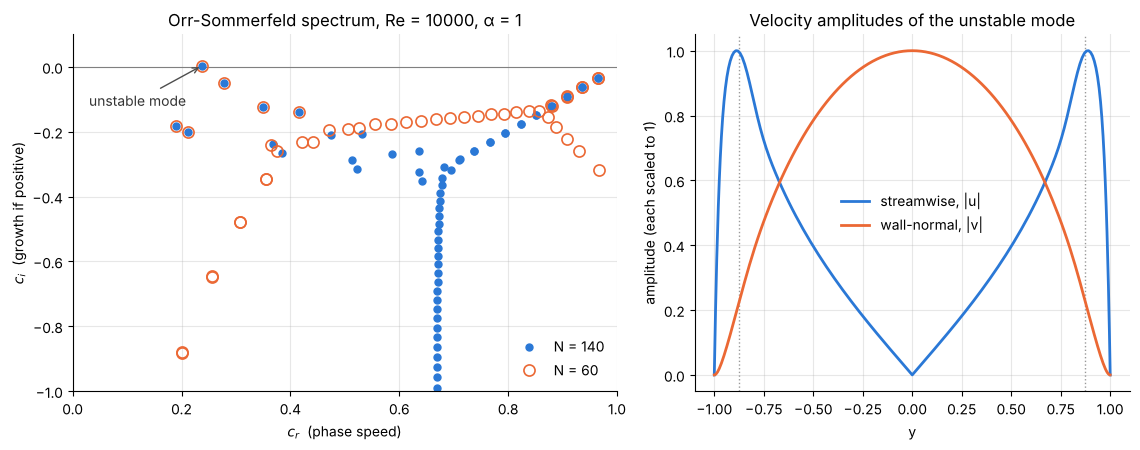

In [12]:
c_coarse = orr_sommerfeld(10_000, 1.0, 60)
c_fine, v_fine = orr_sommerfeld(10_000, 1.0, 140, vectors=True)
y_fine = cheb(140)[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
ax1.axhline(0, color="0.5", lw=0.8)
ax1.plot(c_fine.real, c_fine.imag, "o", ms=5, label="N = 140")
ax1.plot(c_coarse.real, c_coarse.imag, "o", ms=8, mfc="none", mew=1.2, label="N = 60")
ax1.annotate("unstable mode", xy=(orszag.real, orszag.imag), xytext=(0.03, -0.12),
             arrowprops={"arrowstyle": "->", "color": "0.3"}, color="0.2")
ax1.set(xlim=(0, 1), ylim=(-1, 0.1), xlabel="$c_r$  (phase speed)", ylabel="$c_i$  (growth if positive)",
        title="Orr-Sommerfeld spectrum, Re = 10000, α = 1")
ax1.legend(frameon=False, loc="lower right")

v_mode = np.concatenate([[0], v_fine[:, np.argmax(c_fine.imag)], [0]])
u_mode = 1j * (cheb(140)[0] @ v_mode)                            # streamwise velocity from continuity, u = i v'/α (α = 1)
y_critical = np.sqrt(1 - orszag.real)                            # where the flow speed U(y) equals the wave speed c_r
for side in (-1, 1):
    ax2.axvline(side * y_critical, color="0.6", lw=1, ls=":")
ax2.plot(y_fine, np.abs(u_mode) / np.abs(u_mode).max(), label="streamwise, |u|")
ax2.plot(y_fine, np.abs(v_mode) / np.abs(v_mode).max(), label="wall-normal, |v|")
ax2.set(xlabel="y", ylabel="amplitude (each scaled to 1)", title="Velocity amplitudes of the unstable mode")
ax2.legend(frameon=False, loc="center")
fig.tight_layout()

agree = sum(np.abs(c_fine - c).min() < 1e-4 for c in c_coarse)
print(f"{agree} of the {len(c_coarse)} eigenvalues computed with N = 60 agree with N = 140 to 1e-4")
print(f"unstable eigenvalue, distance from Orszag's value: {abs(most_unstable(c_coarse) - orszag):.1e} with N = 60, "
      f"{abs(most_unstable(c_fine) - orszag):.1e} with N = 140")
assert abs(most_unstable(c_fine) - orszag) < 1e-6 and np.sum(c_fine.imag > 0) == 1 and 8 <= agree <= 20   # N = 140: rounding error, so a looser bound

The spectrum has the shape of the letter **Y**. The left arm holds the wall modes, which travel
slowly ($c_r$ around 0.2 to 0.4); the one unstable eigenvalue is at its tip, and is called a
Tollmien-Schlichting wave. The right arm holds centre modes that travel at nearly the
centreline speed, and the stem holds heavily damped modes moving at the mean speed
$\tfrac23$. The right panel shows why the unstable mode is called a wall mode: its streamwise
velocity peaks in thin layers near the walls, close to the positions (dotted) where the flow
speed equals the wave speed, and vanishes on the centreline.

The comparison of resolutions is instructive. With $N = 60$ the unstable eigenvalue is right
to all eight published digits, yet only about a dozen eigenvalues, those at the tips of the
two arms, agree with the finer computation. The rest lie on a spurious arc that has nothing to do with the
true spectrum. The junction and the stem are where this operator is most **non-normal**, and
its eigenvalues there are extremely sensitive to any perturbation, including discretization
error (notebook 8), so they need many more points than the eigenvalue that matters. Had the
question been about the stem, $N = 60$ would have given a confident wrong answer.

More points are not better for everything. For the unstable eigenvalue $N = 140$ is further
from Orszag's value than $N = 60$, typically $10^{-8}$ against $10^{-9}$ (the exact figure is
rounding error and varies from machine to machine): the $N^8$ growth of rounding errors from
14.1.

**The critical Reynolds number.** Lower the Reynolds number and the growth rate falls. The flow
first becomes unstable at the wavenumber $\alpha = 1.02056$. Find the Reynolds number at which
the largest $c_i$ crosses zero there, by root-finding.

critical Reynolds number at α = 1.02056: 5772.222    (N = 80 gives 5772.222)


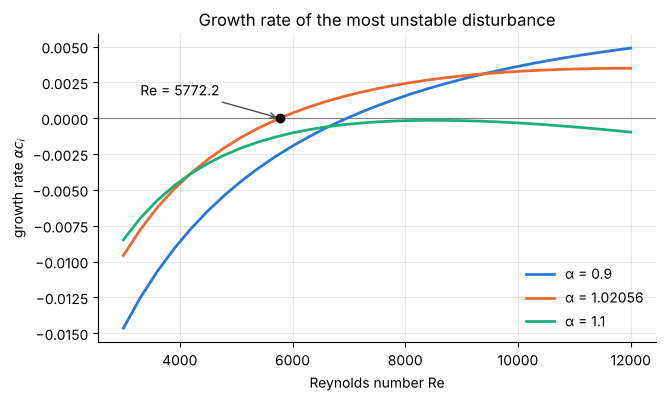

In [13]:
def growth(Re, alpha, N=60):
    """Largest c_i: positive means that some disturbance of wavenumber α grows."""
    return orr_sommerfeld(Re, alpha, N).imag.max()

Re_critical = brentq(growth, 5000, 6500, args=(1.02056,), xtol=1e-4)
print(f"critical Reynolds number at α = 1.02056: {Re_critical:.3f}    (N = 80 gives {brentq(growth, 5700, 5850, args=(1.02056, 80), xtol=1e-4):.3f})")
assert abs(Re_critical - 5772.2) < 0.1

Re_values = np.linspace(3000, 12000, 31)
fig, ax = plt.subplots(figsize=(7.2, 4))
ax.axhline(0, color="0.5", lw=0.8)
for alpha in (0.9, 1.02056, 1.1):
    ax.plot(Re_values, [alpha * growth(Re, alpha, 50) for Re in Re_values], label=f"α = {alpha}")
ax.plot(Re_critical, 0, "ko", ms=6)
ax.annotate(f"Re = {Re_critical:.1f}", xy=(Re_critical, 0), xytext=(3300, 0.0016), arrowprops={"arrowstyle": "->", "color": "0.3"})
ax.set(xlabel="Reynolds number Re", ylabel="growth rate $\\alpha c_i$", title="Growth rate of the most unstable disturbance")
ax.legend(frameon=False, loc="lower right");

**Verify.** The crossing is at $Re = 5772.2$, the accepted critical Reynolds number of plane
Poiseuille flow. Of the three wavenumbers shown, $\alpha = 1.02056$ crosses first;
$\alpha = 0.9$ needs a Reynolds number near 7000, and $\alpha = 1.1$ stays just below the axis
throughout (exercise 5 maps out the unstable band).

**What it means, and a caveat.** Linear theory says that below $Re = 5772$ every
infinitesimal disturbance of this kind eventually decays. (Squire's theorem adds that
three-dimensional waves become unstable only at higher $Re$, so the two-dimensional analysis
is enough.) Yet channel flows in the laboratory become turbulent at Reynolds numbers near
1000, far below this value. The eigenvalues are right; the question they answer is too narrow.
They describe the behaviour as $t \to \infty$ of disturbances that stay infinitesimal. The
Orr-Sommerfeld operator is strongly non-normal, and as notebook 8 explained, such an operator
can amplify disturbances by large factors for a finite time even when every eigenvalue
indicates decay. A small but finite disturbance can grow enough in that time for nonlinear
effects to take over. An eigenvalue with $c_i > 0$ is therefore a sufficient condition for
instability, not a necessary one, and a designer should read "$Re_c = 5772$" as an upper
bound on where laminar channel flow can survive, not as a prediction of transition.

## Summary

- A fourth-order problem needs two conditions per end. For clamped conditions write
  $u = (1 - x^2)q$ with $q(\pm1) = 0$; the product rule turns $u''''$ into a combination of
  $D^4$, $D^3$ and $D^2$ acting on $q$, and the interior unknowns stay as they were.
- Simply supported conditions ($w = w'' = 0$) split into two second-order problems.
- `clamped_d4` gives beam deflections to rounding error, frequencies and buckling loads to ten
  digits with $N = 24$, and by Kronecker products the clamped plate benchmark to all its digits.
- The Orr-Sommerfeld equation is the same clamped operator inside a complex generalized
  eigenproblem: Orszag's eigenvalue to eight digits with 50 points, and $Re_c = 5772.2$.
- Rounding errors grow like $N^8$ in fourth-order problems, and the eigenvalues of non-normal
  operators can be far more sensitive than the one of interest. Use the $N$ the problem needs,
  and compare two resolutions.

## Exercises

1. **The second buckling mode.** With $N = 24$, compute the second and third buckling loads of
   the clamped column of 14.4 and plot the first three buckled shapes. The second mode is
   antisymmetric, and theory gives $P_2 = k^2$ with $k$ the smallest positive root of
   $\tan k = k$ ($k = 4.4934$, $P_2 = 20.1907$). Confirm this to $10^{-8}$ using `brentq` for
   the root.
2. **A beam on an elastic foundation.** A clamped beam resting on a bed of springs (a railway
   sleeper, a strip footing) satisfies $w'''' + \kappa\,w = 1$ on $[-1, 1]$. Solve it for
   $\kappa = 0$, 64 and 4096 with $N = 32$ and plot the three deflections, each divided by its
   largest value. Report the centre deflection for each $\kappa$ and compare it with $1/\kappa$,
   the deflection of an infinitely long beam on the same foundation. Explain what you see near
   the supports for $\kappa = 4096$.
3. **A simply supported plate.** With $w = 0$ and zero bending moment on every edge of the
   square, the plate equation $\nabla^4w = 1$ splits into two Poisson problems,
   $\nabla^2m = 1$ and $\nabla^2w = m$, each with zero boundary values (use the Laplacian of
   notebook 6). With $N = 24$, compute the centre deflection and confirm the handbook value
   $0.00406235\,p\,a^4/D_p$ (that is, $w(0,0) = 0.0649976$ on the square of side 2). By what
   factor is the clamped plate stiffer?
4. **The fundamental frequency of a clamped plate.** Free vibrations of the plate of 14.5
   satisfy $\nabla^4w = \lambda w$ with the same boundary conditions. Compute the smallest
   eigenvalue of the matrix $L$ of 14.5 with $N = 16$ and $N = 20$, and compare the frequency
   parameter $4\sqrt{\lambda_1}$ (which is $\omega a^2\sqrt{\rho h/D_p}$ for a plate of side
   $a$) with the handbook value 35.985. What is the multiplicity of the second eigenvalue, and
   why?
5. **The band of unstable wavenumbers.** At $Re = 7500$, compute the largest $c_i$ for 21
   equally spaced wavenumbers $0.8 \le \alpha \le 1.2$ with $N = 50$ and plot it. Then use
   `brentq` to find the two neutral wavenumbers at which it crosses zero. Repeat at
   $Re = 6000$ and describe how the unstable band changes as $Re$ falls towards 5772.